# Sistema de gerenciamento de livros
Gabriel das Chagas Silva | Anhanguera | Engenharia de Software

Disciplina: Linguagem de Programação. Notebook compatível com Google Colab. Resultados desta entrega executados localmente em Python em 13/10/2026.

No Colab: Arquivo > Fazer upload de notebook; depois Ambiente de execução > Executar tudo. Se faltar uma biblioteca, instale matplotlib, seaborn, pandas, scikit-learn e tensorflow com pip.

## Importações e classe Livro

In [1]:
from collections import defaultdict
from dataclasses import dataclass
import json
import matplotlib.pyplot as plt

@dataclass
class Livro:
    titulo: str
    autor: str
    genero: str
    quantidade: int

# A lista começa vazia, como solicitado no roteiro.
livros = []

## Funções de cadastro, listagem e busca

In [2]:
def cadastrar_livro(titulo, autor, genero, quantidade):
    campos = [titulo.strip(), autor.strip(), genero.strip()]
    if not all(campos):
        raise ValueError('Título, autor e gênero são obrigatórios.')
    if type(quantidade) is not int or quantidade < 0:
        raise ValueError('Quantidade deve ser um inteiro não negativo.')
    livro = Livro(*campos, quantidade)
    livros.append(livro)
    return livro

def listar_livros():
    # Livros sem exemplares disponíveis permanecem no cadastro.
    return [livro for livro in livros if livro.quantidade > 0]

def buscar_livro(titulo):
    termo = titulo.strip().casefold()
    return [livro for livro in livros if livro.titulo.casefold() == termo]

def gerar_grafico():
    totais = defaultdict(int)
    for livro in livros:
        totais[livro.genero] += livro.quantidade
    fig, ax = plt.subplots(figsize=(8, 4))
    barras = ax.bar(list(totais), list(totais.values()), color='#2878a0')
    ax.bar_label(barras)
    ax.set(title='Exemplares disponíveis por gênero', ylabel='Exemplares')
    ax.set_ylim(0, max(totais.values(), default=0) + 2)
    fig.tight_layout()
    fig.savefig('livros_por_genero.png', dpi=180)
    plt.show()
    return dict(totais)

## Demonstração com dados fictícios de cadastro

LIVROS DISPONÍVEIS
Python para iniciantes | Ana Souza | Tecnologia | 4
Algoritmos em Python | Bruno Lima | Tecnologia | 3
O jardim das estrelas | Carla Santos | Ficção | 5
Viagem ao futuro | Diego Alves | Ficção | 2
História da cidade | Eva Rocha | História | 1

BUSCA POR TÍTULO
[Livro(titulo='Python para iniciantes', autor='Ana Souza', genero='Tecnologia', quantidade=4)]
Busca sem resultado: []


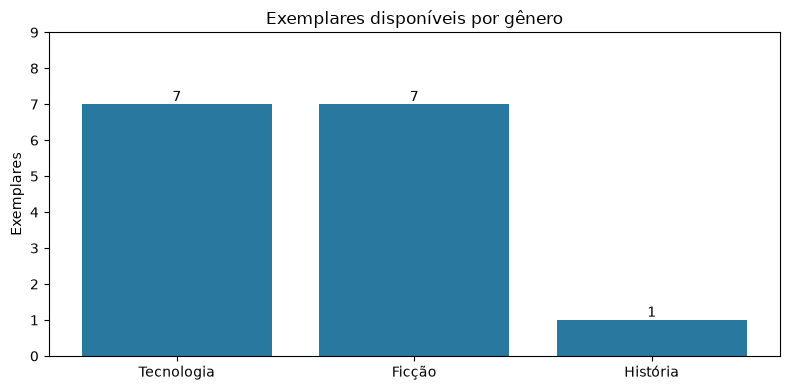

Exemplares por gênero: {'Tecnologia': 7, 'Ficção': 7, 'História': 1}


In [3]:
cadastrar_livro('Python para iniciantes', 'Ana Souza', 'Tecnologia', 4)
cadastrar_livro('Algoritmos em Python', 'Bruno Lima', 'Tecnologia', 3)
cadastrar_livro('O jardim das estrelas', 'Carla Santos', 'Ficção', 5)
cadastrar_livro('Viagem ao futuro', 'Diego Alves', 'Ficção', 2)
cadastrar_livro('História da cidade', 'Eva Rocha', 'História', 1)
cadastrar_livro('Livro esgotado', 'Fábio Costa', 'História', 0)
print('LIVROS DISPONÍVEIS')
for livro in listar_livros():
    print(f'{livro.titulo} | {livro.autor} | {livro.genero} | {livro.quantidade}')
print('\nBUSCA POR TÍTULO')
print(buscar_livro(' PYTHON PARA INICIANTES '))
print('Busca sem resultado:', buscar_livro('Título inexistente'))
totais = gerar_grafico()
print('Exemplares por gênero:', totais)

## Verificações de funcionamento

In [4]:
assert len(livros) == 6 and len(listar_livros()) == 5
assert buscar_livro('python para iniciantes')[0].quantidade == 4
assert buscar_livro('inexistente') == []
for quantidade in [-1, 1.5]:
    try:
        cadastrar_livro('Teste', 'Autor', 'Teste', quantidade)
    except ValueError:
        pass
    else:
        raise AssertionError('Quantidade inválida aceita.')
try:
    cadastrar_livro('', 'Autor', 'Teste', 1)
except ValueError:
    pass
else:
    raise AssertionError('Título vazio aceito.')
assert totais == {'Tecnologia': 7, 'Ficção': 7, 'História': 1}
print('TESTES: cadastro, busca, disponibilidade e validação aprovados.')
with open('resultados.json', 'w', encoding='utf-8') as arquivo:
    json.dump({'titulos': len(livros), 'disponiveis': len(listar_livros()),
               'exemplares': sum(totais.values()), 'generos': totais}, arquivo,
              ensure_ascii=False, indent=2)

TESTES: cadastro, busca, disponibilidade e validação aprovados.
